<a href="https://colab.research.google.com/github/Ahmedhaiba1/ML-project/blob/main/Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import pandas as pd

df = pd.read_csv("H2.csv")
print(df.shape)
df.head()

(79330, 31)


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


In [15]:
# 1) Remove hidden spaces from all text columns
text_cols = df.select_dtypes(exclude="number").columns
for c in text_cols:
    df[c] = df[c].str.strip()

# 2) Real missing values (empty cells)
print("Missing values:")
print(df.isna().sum()[df.isna().sum() > 0])

# 3) "NULL" written as a word (pandas does not count these as missing)
print("\nNULL as text:")
print("Agent  :", (df["Agent"] == "NULL").sum())
print("Company:", (df["Company"] == "NULL").sum())

# 4) Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5) How many bookings were canceled?
print("\nTarget balance:")
print(df["IsCanceled"].value_counts(normalize=True).round(3))

Missing values:
Children     4
Country     24
dtype: int64

NULL as text:
Agent  : 8131
Company: 75641

Duplicate rows: 25902

Target balance:
IsCanceled
0    0.583
1    0.417
Name: proportion, dtype: float64


In [16]:
# Proof 1: ReservationStatus vs IsCanceled
print(pd.crosstab(df["ReservationStatus"], df["IsCanceled"]))

# Proof 2: RequiredCarParkingSpaces vs IsCanceled
print("\n", pd.crosstab(df["RequiredCarParkingSpaces"], df["IsCanceled"]))

# Proof 3: did the hotel change the room?
df["room_changed"] = df["ReservedRoomType"] != df["AssignedRoomType"]
print("\nCancel rate by room_changed:")
print(df.groupby("room_changed")["IsCanceled"].mean().round(3))

df = df.drop(columns="room_changed")   # remove the helper column again


IsCanceled             0      1
ReservationStatus              
Canceled               0  32186
Check-Out          46228      0
No-Show                0    916

 IsCanceled                    0      1
RequiredCarParkingSpaces              
0                         44302  33102
1                          1921      0
2                             3      0
3                             2      0

Cancel rate by room_changed:
room_changed
False    0.453
True     0.058
Name: IsCanceled, dtype: float64


In [17]:
print(df.groupby("BookingChanges")["IsCanceled"].agg(["mean", "count"]).round(3))
print()
print(df.groupby("TotalOfSpecialRequests")["IsCanceled"].agg(["mean", "count"]).round(3))
print()
print(df.groupby(df["ADR"] == 0)["IsCanceled"].agg(["mean", "count"]).round(3))

                 mean  count
BookingChanges              
0               0.455  69062
1               0.137   7232
2               0.237   2244
3               0.186    467
4               0.206    194
5               0.261     46
6               0.323     31
7               0.053     19
8               0.222      9
9               0.250      4
10              0.000      3
11              0.000      2
12              0.000      1
13              0.000      3
14              0.200      5
15              0.000      3
16              0.000      1
17              0.000      1
18              0.000      1
20              0.000      1
21              0.000      1

                         mean  count
TotalOfSpecialRequests              
0                       0.549  47957
1                       0.220  21420
2                       0.214   8142
3                       0.176   1587
4                       0.106    198
5                       0.038     26

        mean  count
ADR            

In [18]:
import pandas as pd

# 1) Load
df = pd.read_csv("H2.csv")

# 2) Remove hidden spaces from text columns
text_cols = df.select_dtypes(exclude="number").columns
for c in text_cols:
    df[c] = df[c].str.strip()

# 3) Drop the columns that come from the future
leak_cols = ["ReservationStatus", "ReservationStatusDate",
             "RequiredCarParkingSpaces", "AssignedRoomType"]
df = df.drop(columns=leak_cols)

# 4) Strict version: also drop the 3 "maybe" columns
df_strict = df.drop(columns=["BookingChanges", "ADR", "TotalOfSpecialRequests"])

print("df:", df.shape)
print("df_strict:", df_strict.shape)
print(df_strict.columns.tolist())

df: (79330, 27)
df_strict: (79330, 24)
['IsCanceled', 'LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'DepositType', 'Agent', 'Company', 'DaysInWaitingList', 'CustomerType']


In [19]:
print("Before:", df_strict.shape)
print("Duplicates:", df_strict.duplicated().sum())

df_clean = df_strict.drop_duplicates().reset_index(drop=True)

print("After :", df_clean.shape)
print(df_clean["IsCanceled"].value_counts(normalize=True).round(3))

Before: (79330, 24)
Duplicates: 28554
After : (50776, 24)
IsCanceled
0    0.694
1    0.306
Name: proportion, dtype: float64


In [20]:
# Unusual values
guests = df_strict["Adults"] + df_strict["Children"].fillna(0) + df_strict["Babies"]
nights = df_strict["StaysInWeekendNights"] + df_strict["StaysInWeekNights"]

print("Adults == 0              :", (df_strict["Adults"] == 0).sum())
print("No guests at all         :", (guests == 0).sum())
print("Zero nights booked       :", (nights == 0).sum())
print("LeadTime max (days)      :", df_strict["LeadTime"].max())
print("DaysInWaitingList > 0    :", (df_strict["DaysInWaitingList"] > 0).sum())
print("DaysInWaitingList max    :", df_strict["DaysInWaitingList"].max())
print("PreviousCancellations > 0:", (df_strict["PreviousCancellations"] > 0).sum())
print("PreviousCancellations max:", df_strict["PreviousCancellations"].max())

# Skewness: 0 = symmetric, above 1 = strongly skewed
num_features = df_strict.select_dtypes("number").drop(columns="IsCanceled")
print("\nSkewness:")
print(num_features.skew().round(2).sort_values(ascending=False))

Adults == 0              : 390
No guests at all         : 167
Zero nights booked       : 331
LeadTime max (days)      : 629
DaysInWaitingList > 0    : 3443
DaysInWaitingList max    : 391
PreviousCancellations > 0: 5389
PreviousCancellations max: 21

Skewness:
Babies                         44.78
PreviousBookingsNotCanceled    23.12
PreviousCancellations          16.58
DaysInWaitingList              10.31
IsRepeatedGuest                 6.01
Children                        4.34
StaysInWeekNights               2.96
LeadTime                        1.39
StaysInWeekendNights            1.13
ArrivalDateWeekNumber          -0.01
ArrivalDateDayOfMonth          -0.01
ArrivalDateYear                -0.25
Adults                         -0.43
dtype: float64


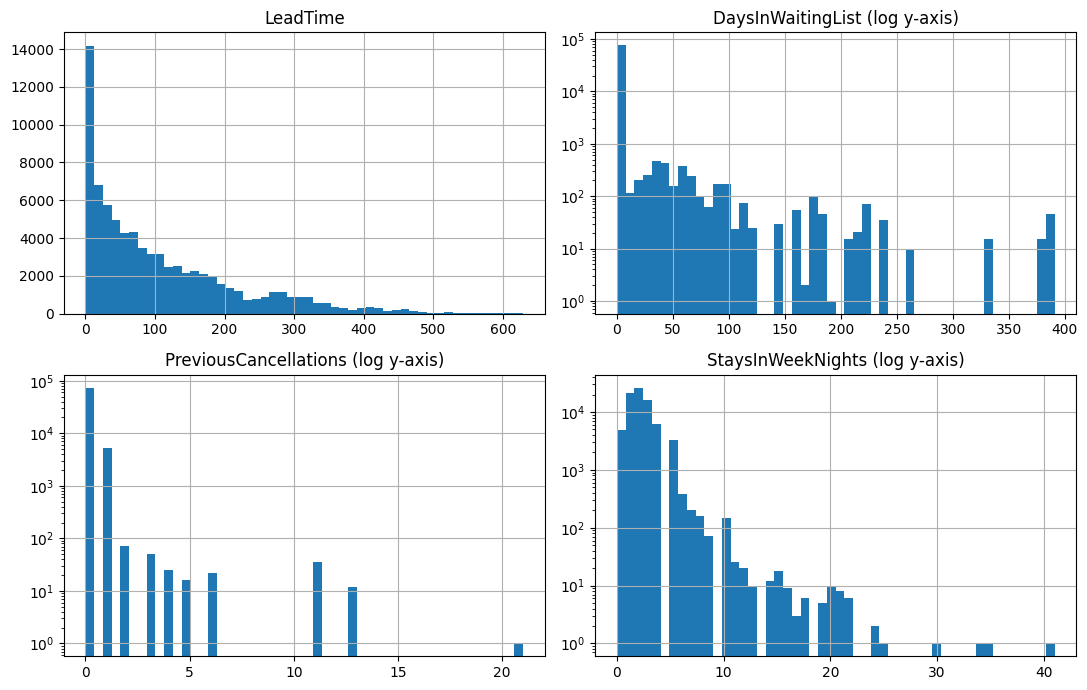

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col, logy in [(axes[0, 0], "LeadTime", False),
                      (axes[0, 1], "DaysInWaitingList", True),
                      (axes[1, 0], "PreviousCancellations", True),
                      (axes[1, 1], "StaysInWeekNights", True)]:
    df_strict[col].hist(bins=50, ax=ax)
    ax.set_title(col + (" (log y-axis)" if logy else ""))
    if logy:
        ax.set_yscale("log")
plt.tight_layout()
plt.show()

In [22]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="IsCanceled")   # features only
y = df_clean["IsCanceled"]                # the answer

print("X columns:", X.shape[1])
print("'IsCanceled' in X?", "IsCanceled" in X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% locked away for the final exam
    stratify=y,          # same cancel rate in both parts
    random_state=42      # same split every time
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Cancel rate train:", round(y_train.mean(), 3))
print("Cancel rate test :", round(y_test.mean(), 3))

X columns: 23
'IsCanceled' in X? False
Train: (40620, 23)  Test: (10156, 23)
Cancel rate train: 0.306
Cancel rate test : 0.306


In [23]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

print(len(num_cols), "numeric:", num_cols)
print()
print(len(cat_cols), "categorical:", cat_cols)
print()
print("Unique values per categorical column:")
print(X_train[cat_cols].nunique())
print()
print("Missing values:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

13 numeric: ['LeadTime', 'ArrivalDateYear', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'DaysInWaitingList']

10 categorical: ['ArrivalDateMonth', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'ReservedRoomType', 'DepositType', 'Agent', 'Company', 'CustomerType']

Unique values per categorical column:
ArrivalDateMonth        12
Meal                     4
Country                156
MarketSegment            8
DistributionChannel      5
ReservedRoomType         8
DepositType              3
Agent                  211
Company                188
CustomerType             4
dtype: int64

Missing values:
Children    3
Country     6
dtype: int64


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numeric columns: fill empty cells with the median, then scale
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical columns: fill empty cells with "Unknown", then one-hot encode
# (values seen fewer than 100 times are grouped together as "infrequent")
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=100, sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

# Learn from TRAIN only, then apply to both
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep  = preprocessor.transform(X_test)

print("Train:", X_train_prep.shape)
print("Test :", X_test_prep.shape)
print("Empty cells left in train:", pd.DataFrame(X_train_prep).isna().sum().sum())

Train: (40620, 121)
Test : (10156, 121)
Empty cells left in train: 0


In [25]:
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"model": name}
    for m in scoring:
        row[m] = round(r["test_" + m].mean(), 3)
    row["fit_seconds"] = round(r["fit_time"].mean(), 1)
    rows.append(row)

results = pd.DataFrame(rows)
print(results)

                 model  accuracy  precision  recall     f1  roc_auc  \
0  Logistic Regression     0.726      0.588   0.347  0.437    0.777   
1        Random Forest     0.762      0.639   0.515  0.570    0.825   

   fit_seconds  
0          1.3  
1          3.5  


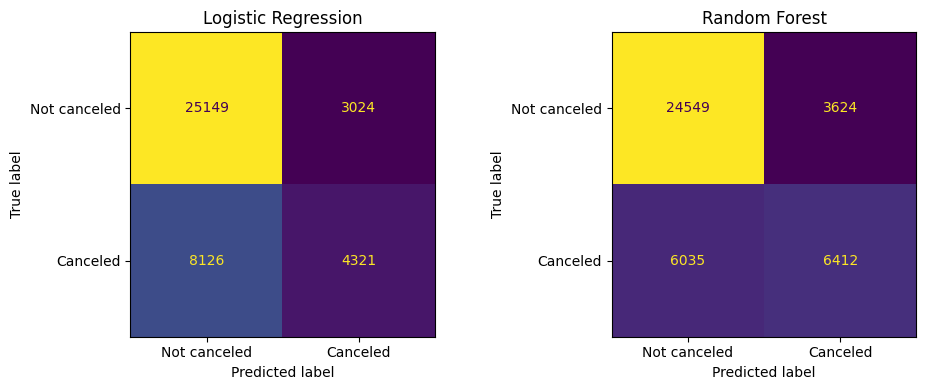

In [26]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    y_pred = cross_val_predict(pipe, X_train, y_train, cv=cv)   # train data only
    ConfusionMatrixDisplay.from_predictions(
        y_train, y_pred, display_labels=["Not canceled", "Canceled"],
        ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()